# OAI — Knee X-ray Concepts Without Images

Step 1 of evaluating the **Osteoarthritis Initiative (OAI)** as a CBMC dataset,
the same way `lidc_concepts.ipynb` did for LIDC. **No images are used here** —
only the ASCII tables in `data/OAI Complete Data_ASCII/`.

The lesson from LIDC: there, the concepts alone predicted the target as well as
the image did (0.842 vs 0.841), so every bottleneck tied and CEM had nothing to
add. Before downloading any images, this notebook checks whether OAI has that
problem.

| | |
|---|---|
| **unit** | one knee at baseline (visit `V00`), both knees per subject |
| **ordinal concepts** | radiologist grades 0-3 per compartment: osteophytes, joint space narrowing, sclerosis, cysts, ... |
| **continuous concepts** | joint space width in **mm** at 13 fixed locations, femorotibial angle in **degrees** |
| **candidate targets** | Kellgren-Lawrence grade (OA), WOMAC knee pain, future knee replacement |

## 0. Run from the repo root

Paths below are relative to the repo root, but Jupyter starts in
`notebooks/`. This walks up until it finds the repo and `cd`s there,
so the notebook works wherever you launched it from.

In [1]:
# Work from the repo root no matter where Jupyter was launched from.
import os
from pathlib import Path

_here = Path.cwd()
for _p in [_here, *_here.parents]:
    if (_p / "cbmc").is_dir() and (_p / "pyproject.toml").exists():
        os.chdir(_p)
        break
else:
    raise RuntimeError(
        f"Could not find the CBMC repo root above {_here}. "
        "Start Jupyter from inside the repo.")
print("working directory:", Path.cwd())

working directory: /Users/yassine/Desktop/CBMC/CBMC


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

OAI = Path("data/OAI Complete Data_ASCII")
assert OAI.is_dir(), f"{OAI} not found"

## 1. What is in the folder

Each table comes as `<Name><visit>.txt` plus PDFs (`_Contents`, `_Stats`,
`_Comments`, `_Descrip`) that document every column. The two-digit suffix is
the visit: `00` baseline, `01` 12 months, `03` 24 months, ... up to `14`;
`99` is the cross-sectional outcomes file.

In [3]:
import re
txt = sorted(p for p in OAI.iterdir() if p.suffix.lower() == ".txt")
groups = {}
for p in txt:
    m = re.match(r"(.+?)(\d{2})?$", p.stem)
    groups.setdefault(m.group(1).lower(), []).append(m.group(2) or "--")

print(f"{len(txt)} tables, {sum(p.stat().st_size for p in txt)/1e9:.2f} GB of text\n")
for name, visits in sorted(groups.items()):
    print(f"  {name:<34}{' '.join(sorted(visits))}")

158 tables, 1.84 GB of text

  acceldatabyday                    06 08
  acceldatabymin                    06 08
  accelerometry                     06 08
  allclinical                       00 01 02 03 04 05 06 07 08 09 10 11 12 13 14
  biomarkers                        00 01 02 03 04 05 06 08 10
  biospec_fnih_joco_assays          --
  biospec_fnih_joco_demographics    --
  biospec_fnih_labcorp              00 01 03
  boneancillarystudy                --
  clinical_fnih                     --
  covidq                            97
  enrollees                         --
  flxr_kneealign_cooke              01 03 05 06
  flxr_kneealign_duryea             01 03 05 06
  hxr_sq                            00 01 06
  hxr_sq_summary                    --
  hxr_sq_ucsf                       00 01 06
  kmri_fnih_boneshape_imorphics     00 01 03
  kmri_fnih_qcart_biomediq          00 01 03
  kmri_fnih_qcart_chondrometrics    00 01 03
  kmri_fnih_sbp_qmetrics            00 01 03
  kmri_poma_incoa

## 2. File format

Pipe-delimited. Coded fields are stored as `"<code>: <label>"`, e.g.
`"1: Right"` or `"2: 2"`, and missing values as `".: Missing Form/Incomplete
Workbook"`. Column names are upper case in most files but not all
(`kxr_qjsw_duryea00.txt` has `readprj`), so everything is upper-cased on load.

Two helpers handle all of it.

In [4]:
def load(name):
    """Read one OAI table, everything as text, upper-case column names."""
    path = next(p for p in OAI.iterdir() if p.name.lower() == name.lower())
    df = pd.read_csv(path, sep="|", dtype=str, low_memory=False)
    df.columns = [c.upper() for c in df.columns]
    return df

def coded(s):
    """'2: 2' -> 2.0,  '1: Right' -> 1.0,  '.: Missing ...' -> NaN,  '4.12' -> 4.12"""
    return pd.to_numeric(s.astype(str).str.split(":").str[0].str.strip(),
                         errors="coerce")

sq_raw = load("KXR_SQ_BU00.txt")
print(sq_raw.iloc[:3, :12].to_string())

        ID      SIDE READPRJ VERSION    V00BARCDBU V00XROSFM V00XRSCFM V00XRCYFM V00XRJSM V00XRCHM V00XROSTM V00XRSCTM
0  9000099  1: Right      15     0.9  016600839603      0: 0      0: 0      0: 0        0     0: 0      1: 1      0: 0
1  9000099   2: Left      15     0.9  016600839603      0: 0      0: 0      0: 0        0     0: 0      0: 0      0: 0
2  9000296  1: Right      15     0.9  016600175004      0: 0      0: 0      0: 0        1     0: 0      1: 1      0: 0


## 3. Subjects

4,796 participants. The **cohort** matters: *progression* subjects already had
symptomatic OA at enrolment, *incidence* subjects only had risk factors. Each
contributes two knees.

In [5]:
enr = load("Enrollees.txt")
print(f"subjects: {len(enr)}\n")
for col, label in [("V00COHORT", "cohort"), ("P02SEX", "sex"), ("P02RACE", "race")]:
    print(label)
    for k, v in enr[col].value_counts().items():
        print(f"  {k:<45}{v:5d}  ({v/len(enr):.1%})")
    print()

subjects: 4796

cohort
  2: Incidence                                  3284  (68.5%)
  1: Progression                                1390  (29.0%)
  3: Non-exposed control group                   122  (2.5%)

sex
  2: Female                                     2804  (58.5%)
  1: Male                                       1992  (41.5%)

race
  1: White or Caucasian                         3790  (79.0%)
  2: Black or African American                   874  (18.2%)
  0: Other Non-white                              82  (1.7%)
  3: Asian                                        45  (0.9%)
  .: Missing Form/Incomplete Workbook              5  (0.1%)



## 4. The inputs — which X-rays exist

`XRay00.txt` lists every baseline radiograph. The one the concepts are read
from is the **bilateral PA fixed-flexion knee** film: one image showing both
knees. The barcode column (`V00XRBARCD`) is what links a concept row to an
image file.

**The images themselves are not in this folder** — these tables only describe
them. They have to be obtained separately before training.

In [6]:
xr = load("XRay00.txt")
print(xr.V00EXAMTP.value_counts().to_string())
knee = xr[xr.V00EXAMTP == "Bilateral PA Fixed Flexion Knee"]
print(f"\nbaseline bilateral knee films: {len(knee)}  "
      f"(-> up to {2*len(knee)} knees)")

V00EXAMTP
AP Pelvis                          4796
Bilateral PA Fixed Flexion Knee    4795
PA Right Hand                      3437
PA Bilateral Hand                   999
PA Left Hand                        825
Lateral Left Knee                   122
Lateral Right Knee                  122
PA Hand                              66
PA Fixed Flexion Right Knee           1
PA Fixed Flexion Left Knee            1

baseline bilateral knee films: 4795  (-> up to 9590 knees)


## 5. Ordinal concepts — semi-quantitative grades (`KXR_SQ_BU00`)

Boston University readings, 0-3 per feature and compartment
(`M` medial / `L` lateral, `F` femur / `T` tibia), plus the KL grade (0-4).

The same knee can be read in **several reading projects** (`READPRJ`).
Project 15 covers nearly every knee; 37 and 43 are re-reads of subsets. We keep
project 15 so each knee appears once.

In [7]:
print(sq_raw.groupby("READPRJ").size().rename("knees").to_string(), "\n")

sq = sq_raw[sq_raw.READPRJ == "15"].copy()

GRADES = {   # column suffix -> readable name
    "XROSFM": "osteophyte_fem_med",  "XROSFL": "osteophyte_fem_lat",
    "XROSTM": "osteophyte_tib_med",  "XROSTL": "osteophyte_tib_lat",
    "XRJSM":  "jsn_med",             "XRJSL":  "jsn_lat",
    "XRSCFM": "sclerosis_fem_med",   "XRSCFL": "sclerosis_fem_lat",
    "XRSCTM": "sclerosis_tib_med",   "XRSCTL": "sclerosis_tib_lat",
    "XRCYFM": "cyst_fem_med",        "XRCYFL": "cyst_fem_lat",
    "XRCYTM": "cyst_tib_med",        "XRCYTL": "cyst_tib_lat",
    "XRCHM":  "chondrocalc_med",     "XRCHL":  "chondrocalc_lat",
    "XRATTM": "attrition_tib_med",   "XRATTL": "attrition_tib_lat",
}
knees = pd.DataFrame({"ID": sq.ID.values, "SIDE": coded(sq.SIDE).values,
                      "barcode": sq.V00BARCDBU.values})
for c, name in GRADES.items():
    knees[name] = coded(sq["V00" + c]).values
knees["KL"] = coded(sq.V00XRKL).values
GRADE_COLS = list(GRADES.values())

print(f"knees: {len(knees)} from {knees.ID.nunique()} subjects "
      f"(SIDE 1 = right, 2 = left)\n")
print("value counts (NaN = not graded):")
print(knees[GRADE_COLS + ["KL"]]
      .apply(lambda s: s.value_counts(dropna=False)).T
      .fillna(0).astype(int).to_string())

READPRJ
15    8982
37    3831
43    3853 

knees: 8982 from 4491 subjects (SIDE 1 = right, 2 = left)

value counts (NaN = not graded):
                     0.0   1.0   2.0   3.0  4.0   NaN
osteophyte_fem_med  3007  1206   547   747    0  3475
osteophyte_fem_lat  3345  1265   472   425    0  3475
osteophyte_tib_med  2150  2557   513   287    0  3475
osteophyte_tib_lat  3440  1439   318   310    0  3475
jsn_med             5783  1939   996   203    0    61
jsn_lat             8193   371   264    93    0    61
sclerosis_fem_med   3740  1000   680    86    0  3476
sclerosis_fem_lat   5044   233   192    37    0  3476
sclerosis_tib_med   3659  1052   686   109    0  3476
sclerosis_tib_lat   5072   218   186    30    0  3476
cyst_fem_med        5458    48     0     0    0  3476
cyst_fem_lat        5495    11     0     0    0  3476
cyst_tib_med        5262   244     0     0    0  3476
cyst_tib_lat        5466    40     0     0    0  3476
chondrocalc_med     5227   279     0     0    0  3476
c

### Missing grades are not random — they leak the target

Osteophyte, sclerosis, cyst and attrition grades are filled in for only about
60% of knees. The table below shows which ones: **every** KL >= 2 knee is
graded, and the missing ones are all KL 0 or 1. A model given `NaN` would learn
"missing means no OA" — reading the answer from the reading protocol, not from
the concept.

So missing grades are set to **0** (feature not seen). Only joint space
narrowing and KL were graded for every knee.

In [8]:
print(pd.crosstab(knees.KL, knees.osteophyte_fem_med.isna().rename("osteophyte grade missing")))
knees[GRADE_COLS] = knees[GRADE_COLS].fillna(0)

osteophyte grade missing  False  True 
KL                                    
0.0                         766   2674
1.0                         848    740
2.0                        2362      0
3.0                        1237      0
4.0                         294      0


## 6. Continuous concepts — joint space width (`kxr_qjsw_duryea00`)

Measured automatically (Duryea) in **millimetres**: the minimum medial JSW, and
JSW at fixed positions across the joint (`JSW150` ... `JSW300` medial,
`LJSW700` ... `LJSW900` lateral; the number is the position as a fraction of
the tibial width x 1000). These are genuine real-valued measurements — the
Case 3.5 concepts.

In [9]:
qj_raw = load("kxr_qjsw_duryea00.txt")
JSW = ["MCMJSW", "JSW150", "JSW175", "JSW200", "JSW225", "JSW250", "JSW275", "JSW300",
       "LJSW700", "LJSW750", "LJSW800", "LJSW850", "LJSW900"]
qj = pd.DataFrame({"ID": qj_raw.ID, "SIDE": coded(qj_raw.SIDE)})
for c in JSW:
    qj[c] = pd.to_numeric(qj_raw["V00" + c], errors="coerce")
print(f"knees measured: {len(qj)}   duplicates: {qj.duplicated(['ID','SIDE']).sum()}\n")
print(qj[JSW].describe().loc[["count", "mean", "std", "min", "max"]].round(2).T.to_string())

knees measured: 6245   duplicates: 0

          count  mean   std  min    max
MCMJSW   6187.0  4.15  1.33  0.0   8.49
JSW150   6132.0  4.59  1.36  0.0  10.51
JSW175   6153.0  4.71  1.35  0.0  10.51
JSW200   6179.0  4.89  1.35  0.0  10.41
JSW225   6189.0  5.16  1.37  0.0  10.22
JSW250   6193.0  5.52  1.40  0.0  11.22
JSW275   6191.0  6.01  1.44  0.0  12.13
JSW300   6194.0  6.64  1.50  0.0  14.62
LJSW700  5901.0  7.70  1.90  0.0  13.61
LJSW750  6032.0  7.16  1.73  0.0  13.07
LJSW800  6023.0  6.55  1.67  0.0  12.51
LJSW850  5828.0  6.10  1.64  0.0  12.61
LJSW900  5549.0  6.43  1.74  0.0  16.21


## 7. Continuous concept — knee alignment (`KXR_FTA_DURYEA00`)

Femorotibial angle in **degrees**: negative is valgus, more positive is varus.
Varus loads the medial compartment, so it is a plausible concept for medial OA.
Two reading projects again; we keep 17, the larger one.

In [10]:
fta_raw = load("KXR_FTA_DURYEA00.txt")
print(fta_raw.groupby("READPRJ").size().rename("knees").to_string(), "\n")
fta_raw = fta_raw[fta_raw.READPRJ == "17"]
fta = (pd.DataFrame({"ID": fta_raw.ID, "SIDE": coded(fta_raw.SIDE),
                     "FTA": pd.to_numeric(fta_raw.V00FTANGLE, errors="coerce")})
       .drop_duplicates(["ID", "SIDE"]))
print(fta.FTA.describe().round(2).to_string())

READPRJ
17    6178
45    1232 

count    6149.00
mean       -5.49
std         2.58
min       -16.33
25%        -7.00
50%        -5.52
75%        -4.06
max         8.25


## 8. Candidate targets

* **KL grade** — the classic OAI / CBM target (Koh et al. 2020). `KL >= 2` is
  the standard definition of radiographic OA.
* **WOMAC knee pain** (0-20, per knee, from `AllClinical00`). What the patient
  feels, not what the radiologist sees.
* **Total knee replacement** during follow-up (`OUTCOMES99`, per knee,
  adjudicated or self-reported).

Plus age and BMI, which are not concepts but are known OA risk factors.

In [11]:
cl = load("AllClinical00.txt")
clin = pd.DataFrame({
    "ID":     cl.ID,
    "AGE":    pd.to_numeric(cl.V00AGE, errors="coerce"),
    "BMI":    pd.to_numeric(cl.P01BMI, errors="coerce"),
    "PAIN_1": pd.to_numeric(cl.V00WOMKPR, errors="coerce"),   # right
    "PAIN_2": pd.to_numeric(cl.V00WOMKPL, errors="coerce"),   # left
})
out = load("OUTCOMES99.txt")
print("right-knee replacement:", out.V99ERKRPCF.value_counts().to_dict(), "\n")
outc = pd.DataFrame({
    "ID":    out.ID,
    "TKR_1": coded(out.V99ERKRPCF).isin([1, 3]).astype(int),   # self-reported or confirmed
    "TKR_2": coded(out.V99ELKRPCF).isin([1, 3]).astype(int),
})

right-knee replacement: {'.: Missing Form/Incomplete Workbook': 4317, '3: Replacement adjudicated, confirmed': 454, '1: Self-reported replacement': 16, '0: Replacement adjudcated,failed to confirm': 9} 



## 9. One table, one row per knee

In [12]:
df = (knees.merge(qj, on=["ID", "SIDE"], how="left")
           .merge(fta, on=["ID", "SIDE"], how="left")
           .merge(clin, on="ID", how="left")
           .merge(outc, on="ID", how="left"))
df["PAIN"] = np.where(df.SIDE == 1, df.PAIN_1, df.PAIN_2)
df["TKR"]  = np.where(df.SIDE == 1, df.TKR_1, df.TKR_2)
df = df.drop(columns=["PAIN_1", "PAIN_2", "TKR_1", "TKR_2"])
df["OA"] = np.where(df.KL.isna(), np.nan, (df.KL >= 2).astype(float))

print(f"{len(df)} knees, {df.ID.nunique()} subjects\n")
print("coverage:")
for c in ["KL", "jsn_med", "MCMJSW", "FTA", "PAIN", "AGE", "BMI"]:
    print(f"  {c:<22}{df[c].notna().mean():6.1%}")
full = df[JSW + ["FTA", "KL"]].notna().all(axis=1)
print(f"\nknees with KL + all 13 JSW + FTA: {full.sum()}")

CACHE = Path("data/processed/oai_knees_v00.csv")
CACHE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(CACHE, index=False)
print(f"saved -> {CACHE}")

8982 knees, 4491 subjects

coverage:
  KL                     99.3%
  jsn_med               100.0%
  MCMJSW                 68.8%
  FTA                    68.4%
  PAIN                  100.0%
  AGE                   100.0%
  BMI                    99.9%

knees with KL + all 13 JSW + FTA: 5268
saved -> data/processed/oai_knees_v00.csv


## 10. Target distributions

KL grade
  0:  3440  (38.6%)  ###########################################
  1:  1588  (17.8%)  ###################
  2:  2362  (26.5%)  #############################
  3:  1237  (13.9%)  ###############
  4:   294  ( 3.3%)  ###

OA (KL >= 2): 43.6% of knees
pain >= 5 / 20: 20.0%   pain == 0: 44.2%
knee replaced during follow-up: 10.2%


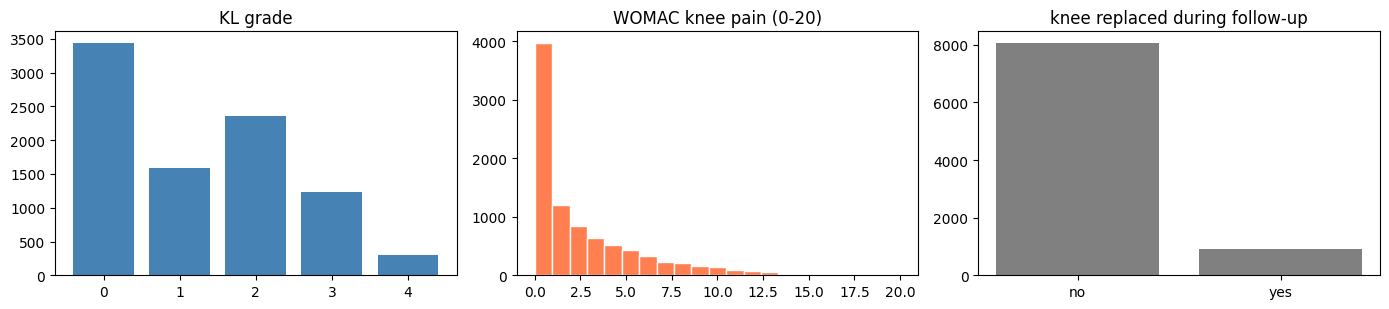

In [13]:
print("KL grade")
for k, v in df.KL.value_counts().sort_index().items():
    print(f"  {int(k)}: {v:5d}  ({v/df.KL.notna().sum():5.1%})  " + "#" * int(v / 80))
print(f"\nOA (KL >= 2): {df.OA.mean():.1%} of knees")
print(f"pain >= 5 / 20: {(df.PAIN >= 5).mean():.1%}   pain == 0: {(df.PAIN == 0).mean():.1%}")
print(f"knee replaced during follow-up: {df.TKR.mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
axes[0].bar(*np.unique(df.KL.dropna(), return_counts=True), color="steelblue")
axes[0].set_title("KL grade")
axes[1].hist(df.PAIN.dropna(), bins=21, color="coral", edgecolor="white")
axes[1].set_title("WOMAC knee pain (0-20)")
axes[2].bar(["no", "yes"], df.TKR.value_counts().sort_index(), color="gray")
axes[2].set_title("knee replaced during follow-up")
plt.tight_layout(); plt.show()

## 11. Concept distributions

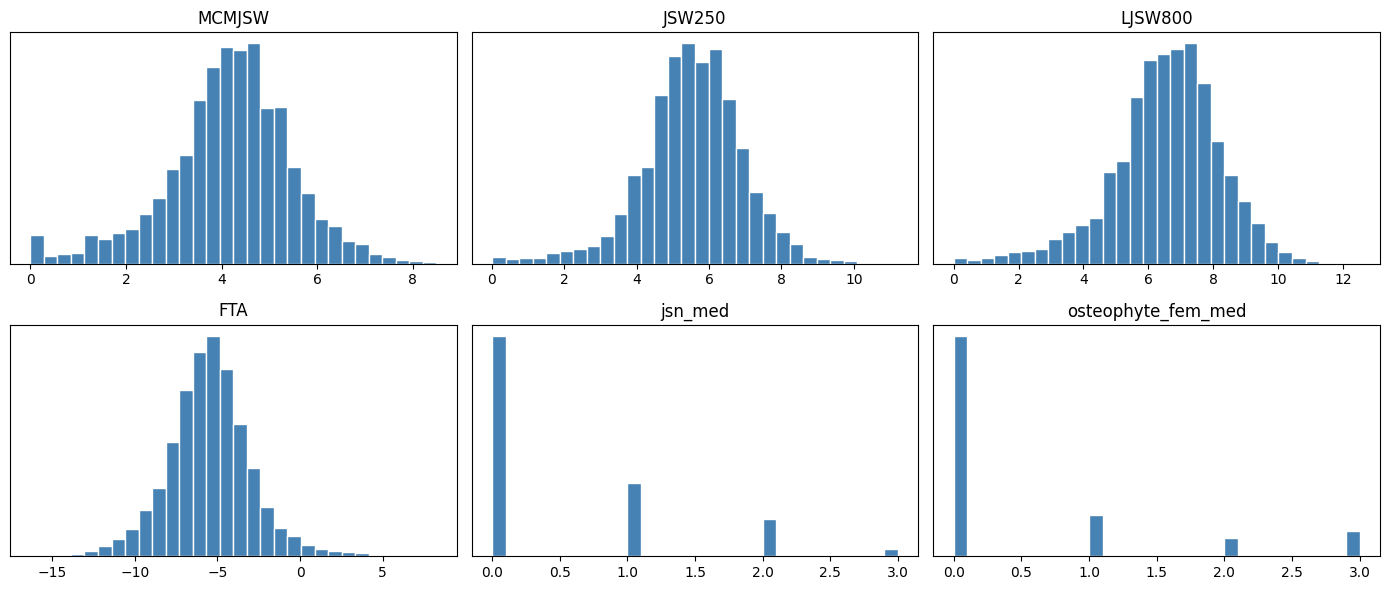

In [14]:
show = ["MCMJSW", "JSW250", "LJSW800", "FTA", "jsn_med", "osteophyte_fem_med"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, name in zip(axes.ravel(), show):
    ax.hist(df[name].dropna(), bins=30, color="steelblue", edgecolor="white")
    ax.set_title(name); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 12. Do the concepts track the targets?

Spearman correlation, since the grades are ordinal and pain is skewed.

In [15]:
CONCEPTS = GRADE_COLS + JSW + ["FTA"]
for target in ["KL", "PAIN", "TKR"]:
    corr = (df[CONCEPTS].corrwith(df[target], method="spearman")
            .sort_values(key=abs, ascending=False))
    print(f"--- {target} ---")
    for name, c in corr.head(8).items():
        print(f"  {name:<22}{c:+.3f}  " + "#" * int(abs(c) * 40))
    print()

--- KL ---
  osteophyte_tib_med    +0.747  #############################
  osteophyte_fem_med    +0.674  ##########################
  jsn_med               +0.674  ##########################
  sclerosis_tib_med     +0.614  ########################
  sclerosis_fem_med     +0.604  ########################
  osteophyte_fem_lat    +0.578  #######################
  osteophyte_tib_lat    +0.557  ######################
  MCMJSW                -0.429  #################

--- PAIN ---
  osteophyte_fem_med    +0.259  ##########
  osteophyte_fem_lat    +0.235  #########
  osteophyte_tib_med    +0.233  #########
  sclerosis_fem_med     +0.214  ########
  osteophyte_tib_lat    +0.213  ########
  sclerosis_tib_med     +0.210  ########
  jsn_med               +0.172  ######
  LJSW700               -0.140  #####

--- TKR ---
  osteophyte_fem_med    +0.296  ###########
  sclerosis_fem_med     +0.274  ##########
  osteophyte_tib_lat    +0.268  ##########
  sclerosis_tib_med     +0.262  ##########
  osteo

## 13. How do the continuous concepts relate to the grades?

JSW in mm should fall as the radiologist's narrowing grade rises. If it did
not, one of the two would be measuring something else.

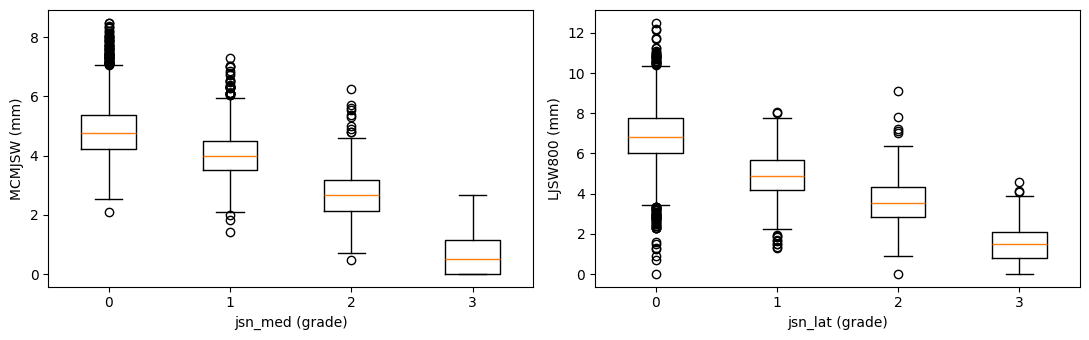

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (g, w) in zip(axes, [("jsn_med", "MCMJSW"), ("jsn_lat", "LJSW800")]):
    d = df[[g, w]].dropna()
    ax.boxplot([d[d[g] == k][w] for k in range(4)], labels=range(4))
    ax.set_xlabel(f"{g} (grade)"); ax.set_ylabel(f"{w} (mm)")
plt.tight_layout(); plt.show()

## 14. Concepts-only ceilings — the LIDC check

A classifier given only the concept values, and **no image**. If it already
matches what an image model can reach, every bottleneck will tie, as on LIDC.

Splits are grouped by **subject**: both knees of a person share age, BMI and
genetics, so a knee-level split would leak.

In [17]:
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, r2_score

def ceiling(data, cols, target, kind):
    d = data[data[target].notna()]
    X, y, g = d[cols], d[target], d.ID
    scores = []
    for tr, te in GroupKFold(5).split(X, y, g):
        if kind == "r2":
            m = HistGradientBoostingRegressor(max_iter=200).fit(X.iloc[tr], y.iloc[tr])
            scores.append(r2_score(y.iloc[te], m.predict(X.iloc[te])))
        else:
            m = HistGradientBoostingClassifier(max_iter=200, class_weight="balanced")
            m.fit(X.iloc[tr], y.iloc[tr])
            scores.append(balanced_accuracy_score(y.iloc[te], m.predict(X.iloc[te]))
                          if kind == "bal" else
                          roc_auc_score(y.iloc[te], m.predict_proba(X.iloc[te])[:, 1]))
    return np.mean(scores), np.std(scores)

df["PAIN5"] = np.where(df.PAIN.isna(), np.nan, (df.PAIN >= 5).astype(float))
SETS = {
    "continuous only (13 JSW + FTA)": JSW + ["FTA"],
    "grades only (18 SQ, no KL)":     GRADE_COLS,
    "grades + continuous":            GRADE_COLS + JSW + ["FTA"],
    "KL grade alone":                 ["KL"],
    "everything + age + BMI":         GRADE_COLS + JSW + ["FTA", "KL", "AGE", "BMI"],
}
TASKS = [("OA (KL >= 2)", "OA", "bal"), ("pain >= 5", "PAIN5", "bal"),
         ("pain 0-20", "PAIN", "r2"), ("knee replacement", "TKR", "auc")]

rows = []
for tname, target, kind in TASKS:
    for sname, cols in SETS.items():
        if target == "OA" and ("KL" in cols):
            continue                           # KL defines the target
        m, s = ceiling(df, cols, target, kind)
        rows.append({"target": tname, "metric": kind, "concepts": sname,
                     "score": f"{m:.3f} ± {s:.3f}"})
res = pd.DataFrame(rows)
print(res.pivot(index="concepts", columns="target", values="score")
         .loc[list(SETS)].to_string())
print("\nmetrics: OA and pain>=5 balanced accuracy, pain 0-20 R², replacement AUC")

target                           OA (KL >= 2) knee replacement      pain 0-20      pain >= 5
concepts                                                                                    
continuous only (13 JSW + FTA)  0.778 ± 0.012    0.675 ± 0.022  0.007 ± 0.008  0.556 ± 0.010
grades only (18 SQ, no KL)      0.961 ± 0.004    0.738 ± 0.015  0.035 ± 0.023  0.596 ± 0.010
grades + continuous             0.963 ± 0.002    0.712 ± 0.020  0.028 ± 0.015  0.573 ± 0.010
KL grade alone                            NaN    0.792 ± 0.021  0.077 ± 0.014  0.617 ± 0.013
everything + age + BMI                    NaN    0.755 ± 0.014  0.064 ± 0.016  0.596 ± 0.010

metrics: OA and pain>=5 balanced accuracy, pain 0-20 R², replacement AUC


## 15. What this means for CBMC

**OA (KL >= 2) gives both settings in one dataset.**

* With the **radiologist grades**, the concepts explain OA almost completely
  (~0.96). KL is *defined* from narrowing and osteophytes, so this is the
  LIDC situation again: every bottleneck should tie.
* With only the **continuous concepts** (JSW in mm + alignment angle), the
  ceiling drops to ~0.78. The X-ray still shows the osteophytes, but the
  bottleneck is not told about them. A scalar CBM should stall near 0.78; a
  CEM can carry the rest in its embeddings. That is the incomplete-concept
  experiment, with genuinely continuous concepts, which LIDC could not give us.

**Pain is too weak.** Nothing here predicts it (R² below 0.1). The image may
carry a little more, but the signal is small enough that differences between
bottlenecks would be lost in noise.

**Knee replacement is possible but harder**: about 10% positives, and the
concepts-only AUC stays below 0.8.

Caveats:
* JSW and FTA are measured on ~69% of knees, so the continuous-concept setting
  has about 6,000 knees, not 9,000.
* Missing grades were set to 0 (Section 5). That matches how the readers
  skipped knees without OA, but confirm it in `kXR_SQ_BU_Descrip.pdf` before
  training.

## 16. Next step: images

These tables carry no pixels. The bilateral PA fixed-flexion films must be
obtained separately, cropped into one image per knee, and matched to
`ID` + `SIDE` (or the barcode) in `data/processed/oai_knees_v00.csv`.